# Data Extraction and Table Overview
### Balanced package for the Sydney student-rent project (8 sources)

**Purpose.** This notebook does two jobs before the main analysis notebook is changed:
1. **Extracts** every table the balanced package needs, from the public source, into tidy files.
2. **Explains each table** in plain terms: what one row is, what the columns mean, how big it is, how complete it is, how it joins to the others, and what it will be used for.

It does **not** clean for analysis or build the analysis panel. Cleaning rules, exposure measures and the grouping of postcodes stay in the project notebook.

**How to read it.** Each section is one source and follows the same pattern: *What it is → Extract → Overview → Data dictionary → Quality notes → Role in the project*. The last sections show how the tables connect and list the decisions to make before editing the project notebook.

## The balanced package

| # | Source | Group | Role in the project |
|---|---|---|---|
| A | NSW rental bond lodgements | Core | The outcome: new-lease weekly rent |
| B | CRICOS (campuses and courses) | Core | Where the higher-education campuses are |
| C | Dept of Education enrolments by SA4 | Core | How many international students study in each region |
| D | ABS geography (postcode boundaries and correspondences) | Core | Maps postcodes to regions and gives postcode centres |
| E | NSW DCJ Rent tables (2018–2022) | Enrichment | Pre-COVID check; fills the 2019–2020 gap |
| F | ABS Census 2021 (postcode tables) | Enrichment | Second exposure measure; checks the first |
| G | Home Affairs BP0019 (student visa holders present) | Enrichment | Better phase definition; seasonality of student presence |
| H | City of Sydney Housing Audit 2015–2025 | Enrichment | Supply of student rooms in the City of Sydney |

**Not in the package** (decided against): GTFS transport timetables, student room price lists, bond refunds, development applications, Airbnb, NSW Housing Supply, CPI.

## Outputs
All extracted tables are written to `processed/extracted/` as Parquet or CSV, and a catalogue of them is saved as `data_catalogue.csv`.

# 1. Setup

In [1]:
from __future__ import annotations

import io
import json
import os
import re
import time
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import openpyxl
from defusedxml import ElementTree as ET        # safe parser for XML inside downloaded files
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from bs4 import BeautifulSoup
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

# Data folder: set RENT_DATA_ROOT to use a different location; otherwise use the project's data/ folder.
_env = os.environ.get("RENT_DATA_ROOT")
if _env:
    ROOT = Path(_env)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "processed").exists())
RAW, OUT = ROOT / "raw", ROOT / "processed" / "extracted"
OUT.mkdir(parents=True, exist_ok=True)
RAW.mkdir(parents=True, exist_ok=True)
print("Data folder:", ROOT)

HEADERS = {"User-Agent": "Mozilla/5.0 (research project)"}
FORCE = False          # True re-downloads everything, even files that already exist

def md(text: str) -> None:
    display(Markdown(text))

def fetch(url: str, dest: Path, force: bool = FORCE, retries: int = 4) -> Path:
    """Download `url` to `dest` unless it already exists. Retries on timeouts and server errors."""
    dest = Path(dest)
    if dest.exists() and not force:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(retries):
        try:
            r = requests.get(url, headers=HEADERS, timeout=(15, 180), allow_redirects=True)
            r.raise_for_status()
            dest.write_bytes(r.content)
            time.sleep(0.3)
            return dest
        except Exception as exc:
            print(f"  retry {attempt + 1}/{retries} for {dest.name}: {type(exc).__name__}")
            time.sleep(3 + 4 * attempt)
    raise RuntimeError(f"could not download {url}")

def get_text(url: str) -> str:
    for attempt in range(4):
        try:
            r = requests.get(url, headers=HEADERS, timeout=(15, 90)); r.raise_for_status(); return r.text
        except Exception:
            time.sleep(3 + 3 * attempt)
    raise RuntimeError(f"could not read {url}")

def ckan_resources(base: str, package_id: str) -> list[dict]:
    """List the files (resources) of a data.gov.au dataset through its CKAN API."""
    j = json.loads(get_text(f"{base}/data/api/3/action/package_show?id={package_id}"))
    return j["result"]["resources"]

CHECKS = []
def check(label: str, actual, expected, tol: float = 0.0) -> None:
    """Compare an extracted value with the value seen when the source was first inspected (26 Oct 2026)."""
    ok = abs(actual - expected) <= tol if isinstance(actual, (int, float, np.integer, np.floating)) else actual == expected
    CHECKS.append({"check": label, "found": actual, "expected": expected, "ok": "✓" if ok else "✗ (source may have changed)"})

REGISTRY = []
def register(name: str, df: pd.DataFrame, filename: str, grain: str, group: str, role: str, keys: str, period: str) -> None:
    """Write a table to processed/extracted/ and record it in the catalogue."""
    path = OUT / filename
    (df.to_csv(path, index=False) if filename.endswith(".csv") else df.to_parquet(path, index=False))
    REGISTRY.append({"table": name, "file": filename, "one row is": grain, "rows": len(df), "columns": df.shape[1],
                     "size_MB": round(path.stat().st_size / 1e6, 2), "group": group, "role": role, "join keys": keys, "period": period})

def card(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """Compact overview of a table: size, missing values and type of every column."""
    out = pd.DataFrame({"type": df.dtypes.astype(str), "missing %": (df.isna().mean() * 100).round(1),
                        "distinct": df.nunique(dropna=True),
                        "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns]})
    print(f"{name}: {len(df):,} rows × {df.shape[1]} columns | {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB in memory")
    return out

Data folder: /Users/chipi/Desktop/DATA/career_mentor/data


# 2. Source A – NSW rental bond lodgements (core)

## What it is
Every time a landlord or agent starts a tenancy in NSW, a **bond** is lodged with NSW Fair Trading. The published files list each lodgement with the
date, the postcode, the type of dwelling, the number of bedrooms and the **weekly rent**. This is the project's main measure: the rent that a person
moving house actually meets, not the rent paid by people who already live there.

- **One row =** one bond lodged (one new tenancy). There is no bond or tenant identifier.
- **Publisher / licence:** NSW Fair Trading, via nsw.gov.au (Creative Commons Attribution).
- **Files:** one workbook per month (2022 onward) and one per year; the annual files repeat the monthly ones from 2022.
- **Pre-COVID year:** the 2018 file comes from a data.nsw mirror (a test portal), so its provenance should be confirmed. Files for 2019–2020 were not found.

## Extract

In [2]:
BOND_PAGE = "https://www.nsw.gov.au/housing-and-construction/rental-forms-surveys-and-data/rental-bond-data"
BOND_2018_URL = ("https://uatdatansw.dac.nsw.gov.au/data/dataset/b3a7c29c-2443-461a-b474-98aeacef22a8/resource/"
                 "bd48c54d-3a0e-4a9f-a316-dc84bea558ca/download/rentalbond_lodgements_year_2018.csv")
BOND_COLS = ["lodgement_date", "postcode", "dwelling_type", "bedrooms", "weekly_rent"]

def list_bond_files() -> pd.DataFrame:
    """Read the Fair Trading page and list the lodgement workbooks (refunds and bonds-held files are excluded)."""
    soup = BeautifulSoup(get_text(BOND_PAGE), "html.parser")
    rows = []
    for a in soup.find_all("a", href=True):
        h = a["href"]
        if h.lower().endswith(".xlsx") and "/noindex/" in h:
            name = h.rsplit("/", 1)[1].lower()
            if "refund" in name or "held" in name:
                continue
            if "lodg" in name:
                rows.append({"file": h.rsplit("/", 1)[1], "url": h if h.startswith("http") else "https://www.nsw.gov.au" + h,
                             "kind": "annual" if "year" in name else "monthly"})
    return pd.DataFrame(rows).drop_duplicates("file")

def parse_bond_workbook(fp: Path) -> pd.DataFrame:
    """Read one lodgement workbook. The header row is found by name because the title block varies."""
    wb = openpyxl.load_workbook(fp, read_only=True, data_only=True)
    for sn in wb.sheetnames:
        found, rows = False, []
        for r in wb[sn].iter_rows(values_only=True):
            r = tuple(r) + (None,) * 5
            if not found:
                found = bool(r[0]) and str(r[0]).strip().lower().startswith("lodgement date")
                continue
            if r[0] is None and r[1] is None:
                continue
            rows.append(r[:5])
        if found:
            return pd.DataFrame(rows, columns=BOND_COLS)
    raise ValueError(f"no data sheet in {fp.name}")

bond_files = list_bond_files()
frames = []
for r in bond_files.itertuples():
    fp = fetch(r.url, RAW / "nsw_bond" / r.file)
    d = parse_bond_workbook(fp)
    d["source_file"], d["file_kind"] = r.file, r.kind
    frames.append(d)
bond_stack = pd.concat(frames, ignore_index=True)
for c in ["postcode", "bedrooms", "weekly_rent"]:
    bond_stack[c] = pd.to_numeric(bond_stack[c], errors="coerce")        # 'U' (unknown) becomes missing
bond_stack["lodgement_date"] = pd.to_datetime(bond_stack["lodgement_date"], errors="coerce")
bond_stack["dwelling_type"] = bond_stack["dwelling_type"].astype(str).str.strip()
print(f"{len(bond_files)} workbooks ({(bond_files.kind == 'annual').sum()} annual, {(bond_files.kind == 'monthly').sum()} monthly) → {len(bond_stack):,} rows")

62 workbooks (5 annual, 57 monthly) → 3,190,534 rows


**Overlap between annual and monthly files.** From 2022 both exist for the same bonds. The analysis set uses the 2021 annual file plus the monthly files
from January 2022, so nothing is counted twice.

In [3]:
ov = (bond_stack[bond_stack.lodgement_date.dt.year.between(2022, 2025)]
      .assign(year=lambda d: d.lodgement_date.dt.year).groupby(["year", "file_kind"]).size().unstack())
ov["annual ÷ monthly"] = ov["annual"] / ov["monthly"]
display(ov)

is_2021_annual = (bond_stack.file_kind == "annual") & (bond_stack.lodgement_date.dt.year == 2021)
is_monthly_2022 = (bond_stack.file_kind == "monthly") & (bond_stack.lodgement_date >= "2022-01-01")
bond_2021_26 = bond_stack[is_2021_annual | is_monthly_2022].copy()
bond_2021_26["period_source"] = np.where(is_2021_annual[is_2021_annual | is_monthly_2022], "2021 annual file", "2022+ monthly files")

fp18 = fetch(BOND_2018_URL, RAW / "nsw_bond_2018" / "rentalbond_lodgements_year_2018.csv")
b18 = pd.read_csv(fp18, skiprows=3, dtype=str, encoding="utf-8-sig")
b18.columns = BOND_COLS
b18["lodgement_date"] = pd.to_datetime(b18["lodgement_date"], format="%d/%m/%Y", errors="coerce")
for c in ["postcode", "bedrooms", "weekly_rent"]:
    b18[c] = pd.to_numeric(b18[c], errors="coerce")
b18["dwelling_type"] = b18["dwelling_type"].str.strip()
b18 = b18.dropna(subset=["lodgement_date", "postcode"])
b18["source_file"], b18["file_kind"], b18["period_source"] = fp18.name, "annual", "2018 file (data.nsw mirror)"

bond = pd.concat([b18, bond_2021_26], ignore_index=True)
bond["postcode"] = bond["postcode"].astype(int)
bond = bond[["lodgement_date", "postcode", "dwelling_type", "bedrooms", "weekly_rent", "period_source", "source_file"]]
check("bond: workbooks found", len(bond_files), 62)
check("bond: rows in analysis set (2018 + 2021–2026)", len(bond), 2_215_281)
register("bond_lodgements", bond, "bond_lodgements.parquet", "one bond lodged (one new tenancy)", "Core",
         "Outcome: new-lease weekly rent", "postcode (→ ABS POA); lodgement_date", "2018; Jan 2021 – Sep 2026")

file_kind,annual,monthly,annual ÷ monthly
year,,,
2022,330396,330403,1.00
2023,326246,326114,1.00
2024,328183,328183,1.00
2025,322307,322318,1.00


## Overview

In [4]:
card(bond, "bond_lodgements")

bond_lodgements: 2,215,281 rows × 7 columns | 255.2 MB in memory


,type,missing %,distinct,example
lodgement_date,datetime64[us],0.00,2464,2018-04-09 00:00:00
postcode,int64,0.00,621,2000
dwelling_type,str,0.00,16,F
bedrooms,float64,3.40,31,0.00
weekly_rent,float64,1.80,2344,580.00
period_source,str,0.00,3,2018 file (data.nsw mirror)
source_file,str,0.00,59,rentalbond_lodgements_year_2018.csv


In [5]:
bond.sample(6, random_state=1).sort_values("lodgement_date")

,lodgement_date,postcode,dwelling_type,bedrooms,weekly_rent,period_source,source_file
252499,2018-12-10,2478,H,4.00,895.00,2018 file (data.nsw mirror),rentalbond_lodgements_year_2018.csv
1678095,2022-08-18,2455,F,3.00,500.00,2022+ monthly files,RentalBond_Lodgements_August_2022-3.xlsx
1319604,2023-09-29,2486,T,3.00,650.00,2022+ monthly files,RentalBond_Lodgements_September_2023.xlsx
915560,2024-12-24,2564,H,2.00,480.00,2022+ monthly files,rental-bond-lodgements-december-2024.xlsx
637595,2025-10-24,2320,H,4.00,680.00,2022+ monthly files,rentalbond_lodgements_october_2025.xlsx
479328,2026-04-30,2325,H,2.00,460.00,2022+ monthly files,rentalbond_lodgements_april_2026.xlsx


## Data dictionary

| Column | Meaning | Notes |
|---|---|---|
| `lodgement_date` | Day the bond was lodged with Fair Trading | Treated as the tenancy start month |
| `postcode` | Postcode of the rented home | The only location field |
| `dwelling_type` | `F` flat/unit, `H` house, `T` terrace/townhouse/semi, `O` other (can include rooms, garages, car spaces), `U` unknown | A few undefined codes also appear |
| `bedrooms` | Number of bedrooms | Missing means unknown; `0` can mean a studio, or a garage/car space |
| `weekly_rent` | Weekly rent in AUD at the start of the tenancy | Given by the agent or landlord |
| `period_source` | Which file the row came from | Used to avoid double counting |

## Quality notes

,count,share %
rows,2215281,100.00
rent missing,40868,1.84
bedrooms missing,76347,3.45
"rent outside $100–5,000",4215,0.19
dwelling code not F/H/T/O/U,65,0.00
exact duplicate rows,133231,6.01


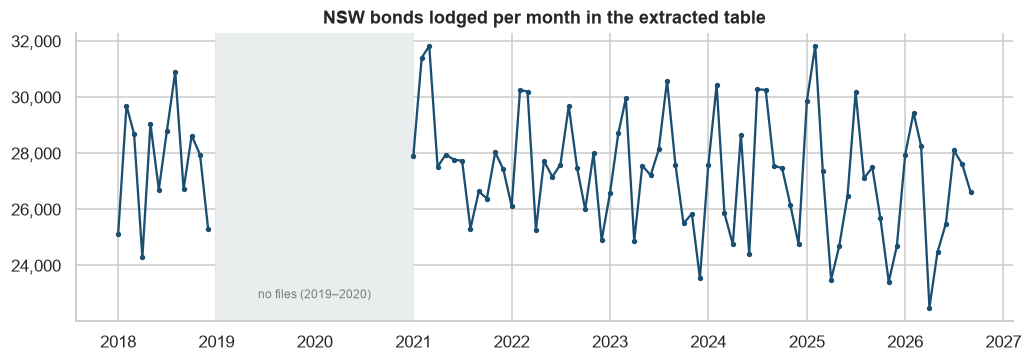

In [6]:
q = pd.DataFrame({
    "rows": [len(bond)],
    "rent missing": [bond.weekly_rent.isna().sum()],
    "bedrooms missing": [bond.bedrooms.isna().sum()],
    "rent outside $100–5,000": [(~bond.weekly_rent.between(100, 5000) & bond.weekly_rent.notna()).sum()],
    "dwelling code not F/H/T/O/U": [(~bond.dwelling_type.isin(list("FHTOU"))).sum()],
    "exact duplicate rows": [bond.duplicated(["lodgement_date", "postcode", "dwelling_type", "bedrooms", "weekly_rent"]).sum()],
}).T.rename(columns={0: "count"})
q["share %"] = (q["count"] / len(bond) * 100).round(2)
display(q)

monthly = bond.assign(month=bond.lodgement_date.dt.to_period("M").dt.to_timestamp()).groupby("month").size()
full = pd.date_range("2018-01-01", "2026-09-01", freq="MS")
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(monthly.reindex(full).index, monthly.reindex(full).values, color="#1b4f72", marker="o", ms=2.5)
ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2020-12-31"), color="#eaeded")
ax.text(pd.Timestamp("2019-12-31"), ax.get_ylim()[0] + 800, "no files (2019–2020)", ha="center", fontsize=8, color="#7b7d7d")
ax.set_title("NSW bonds lodged per month in the extracted table")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.show()

- Duplicate rows are **not** errors: two real bonds can share the same date, postcode, type, bedrooms and rent (common in apartment buildings), and there is no ID to tell them apart.
- Rows with unknown rent, bedrooms or dwelling type are kept here; the project notebook decides what to drop.
- Postcode is the finest location, so any link to a region goes through the ABS postcode correspondences (Source D).

## Role in the project
The **outcome table**. Everything else describes places, times or students around it.

# 3. Source B – CRICOS: institutions, courses and campus locations (core)

## What it is
CRICOS is the national register of education providers and courses that can enrol international students. Four tables are published; they must be
joined to answer "which campuses offer higher-education courses, and where?".

| Table | One row is | Why it is needed |
|---|---|---|
| Institutions | One education provider | Provider type (government/private) |
| Courses | One course offered by a provider | Course level (bachelor, masters…), duration, fee |
| Locations | One teaching location of a provider | **Postcode and address** of the campus |
| Course locations | One course at one location | Links courses to places |

**Important:** CRICOS lists what is *offered*, not how many students attend. It has no enrolment counts. The provider "capacity" column is a registration
ceiling and is not used as a measure of demand.

## Extract

In [7]:
CKAN = "https://data.gov.au"
cr = {r["name"]: r["url"] for r in ckan_resources(CKAN, "cricos") if r.get("format", "").upper() == "CSV"}
need = {"institutions": "CRICOS Institutions.csv", "courses": "CRICOS Courses.csv", "locations": "CRICOS Locations.csv",
        "course_locations": "CRICOS Course Locations.csv"}
cricos = {}
for k, name in need.items():
    fp = fetch(cr[name], RAW / "cricos_full" / name.lower().replace(" ", "-"))
    cricos[k] = pd.read_csv(fp, dtype=str, encoding="utf-8-sig")
print({k: v.shape for k, v in cricos.items()})

{'institutions': (1547, 13), 'courses': (25973, 24), 'locations': (3883, 11), 'course_locations': (46511, 6)}


In [8]:
loc_u = cricos["locations"].drop_duplicates(["CRICOS Provider Code", "Location Name"])
crs_u = cricos["courses"].drop_duplicates(["CRICOS Provider Code", "CRICOS Course Code"])
cricos_cl = (cricos["course_locations"]
             .merge(loc_u[["CRICOS Provider Code", "Location Name", "Location Type", "Address Line 1", "Postcode"]],
                    on=["CRICOS Provider Code", "Location Name"], how="left", validate="m:1")
             .merge(crs_u[["CRICOS Provider Code", "CRICOS Course Code", "Course Name", "Course Level", "Duration (Weeks)",
                           "Tuition Fee", "Field of Education 1 Broad Field", "Expired"]],
                    on=["CRICOS Provider Code", "CRICOS Course Code"], how="left", validate="m:1")
             .merge(cricos["institutions"][["CRICOS Provider Code", "Institution Type"]].drop_duplicates("CRICOS Provider Code"),
                    on="CRICOS Provider Code", how="left", validate="m:1"))
cricos_cl.columns = [re.sub(r"\W+", "_", c.strip()).strip("_").lower() for c in cricos_cl.columns]
cricos_cl = cricos_cl.rename(columns={"location_city": "city", "location_state": "state", "duration_weeks": "duration_weeks"})
print(f"course × location rows: {len(cricos_cl):,} | matched to a postcode: {cricos_cl.postcode.notna().mean():.1%} | matched to course level: {cricos_cl.course_level.notna().mean():.1%}")
check("cricos: course-location rows", len(cricos_cl), 46_511, tol=2_000)
register("cricos_course_locations", cricos_cl, "cricos_course_locations.parquet", "one course offered at one location", "Core",
         "Campus locations and course level", "postcode (→ ABS POA); cricos_provider_code", "Snapshot, Sep 2026")

course × location rows: 46,511 | matched to a postcode: 100.0% | matched to course level: 100.0%


## Overview

In [9]:
card(cricos_cl, "cricos_course_locations")

cricos_course_locations: 46,511 rows × 16 columns | 17.8 MB in memory


,type,missing %,distinct,example
cricos_provider_code,str,0.00,1540,00001K
institution_name,str,0.00,1507,Canberra Institute of Technology
cricos_course_code,str,0.00,25937,078241E
location_name,str,0.00,3743,Canberra Institute of Technology - Vowels cres...
city,str,0.00,1476,BRUCE
state,str,0.00,8,ACT
location_type,str,0.00,3,Location owned and operated by provider
address_line_1,str,0.00,3495,Vowels cres
postcode,str,0.00,803,2617
course_name,str,0.00,10217,ACT Year 12 Certificate


In [10]:
display(cricos_cl[cricos_cl.state == "NSW"].sample(5, random_state=1)[
    ["institution_name", "course_name", "course_level", "location_name", "city", "postcode", "expired"]])

,institution_name,course_name,course_level,location_name,city,postcode,expired
16074,Technical and Further Education Commission,Diploma of Early Childhood Education and Care,Diploma,TAFE NSW Coffs Harbour - Hogbin Drive,COFFS HARBOUR,2450,Yes
16178,Technical and Further Education Commission,Advanced Diploma of Engineering,Advanced Diploma,TAFE NSW Granville,GRANVILLE,2142,No
25389,WHITEHOUSE INSTITUTE PTY LTD,Master of Design,Masters Degree (Coursework),Whitehouse Institute of Design (NSW),SURRY HILLS,2010,No
29692,Signet Institute of Australia,Certificate III in Pathology Collection,Certificate III,KFI - Sydney,FOREST LODGE,2037,No
42872,Australian Professional Training Academy Pty Ltd,Certificate IV in Ageing Support,Certificate IV,Level 4 410 Elizabeth St SURRY HILLS NSW 2010,SURRY HILLS,2010,No


## Data dictionary

| Column | Meaning |
|---|---|
| `cricos_provider_code`, `institution_name`, `institution_type` | The education provider and whether it is government or private |
| `cricos_course_code`, `course_name`, `course_level` | The course; level such as Bachelor Degree, Masters Degree (Coursework), Diploma, Certificate III |
| `location_name`, `address_line_1`, `city`, `state`, `postcode` | Where the course is taught. **Postcode is what links to the rest of the project** |
| `duration_weeks`, `tuition_fee`, `field_of_education_1_broad_field` | Course length, listed fee, subject area |
| `expired` | `Yes` if the course is no longer offered; such rows are dropped in the analysis |

## Quality notes

In [11]:
nsw = cricos_cl[(cricos_cl.state == "NSW") & (cricos_cl.expired == "No")]
HE_LEVEL = r"Bachelor|Master|Doctor|Graduate Cert|Graduate Dip|Associate Degree"
he = nsw[nsw.course_level.fillna("").str.contains(HE_LEVEL, case=False)]
print(f"NSW current course-location rows: {len(nsw):,} | higher-education levels: {len(he):,} ({len(he) / len(nsw):.0%}) | providers: {nsw.cricos_provider_code.nunique()}")
print(f"Expired rows in the whole table: {(cricos_cl.expired == 'Yes').sum():,}")
display(he.groupby("institution_name").size().sort_values(ascending=False).head(8).rename("higher-education course-location rows").to_frame())

NSW current course-location rows: 14,933 | higher-education levels: 6,593 (44%) | providers: 609
Expired rows in the whole table: 861


,higher-education course-location rows
institution_name,
The University of Sydney,690
The University of New South Wales (UNSW),594
The University of Newcastle (UoN),590
University of Wollongong (UoW),588
Western Sydney University,541
University of Technology Sydney (UTS),524
Macquarie University (Macquarie),361
Australian Catholic University Limited,175


- **Postcodes UNSW (2052) and Macquarie (2109) are institution-only codes** that ABS does not publish as postcode areas; the project maps them to the neighbouring
  postcodes 2033 and 2113 (see Source D).
- A large share of rows belong to a few big universities; many small private colleges offer a handful of courses each.

## Role in the project
Gives the **location of every campus** and which are higher-education campuses. The count of higher-education course-location rows is used only to split a
region's enrolments across its campuses (an allocation assumption, not an observed number).

# 4. Source C – Department of Education: international student enrolments by SA4 (core)

## What it is
The Department of Education counts international students on student visas (from the PRISMS system). This table gives counts for each **SA4 region**
(a statistical area; Greater Sydney has 14 of them), split by education sector and broad field of study.

- **One row =** one SA4 × remoteness area × sector × broad field of education.
- **Measures:** `enrolments` and `commencements` for the year to December 2025. A student with two courses counts twice.
- **Place of study, not residence.** Counts below 5 are hidden.

## Extract

In [12]:
DOE_PAGE = "https://www.education.gov.au/node/15221"
m = re.search(r'/download/15221/[^"\']+/document/xlsx', get_text(DOE_PAGE))
doe_url = "https://www.education.gov.au" + m.group(0)
doe_fp = fetch(doe_url, RAW / "doe_sa4" / "intl_student_sa4.xlsx")
doe_head = pd.read_excel(doe_fp, header=None, nrows=5)
doe_period = str(doe_head.iloc[1, 0])
doe = pd.read_excel(doe_fp, header=5, usecols=range(7)).dropna(subset=["State"])
doe.columns = ["state", "sa4_name", "remoteness", "sector_raw", "field_of_education", "enrolments", "commencements"]
doe["enrolments"] = pd.to_numeric(doe["enrolments"], errors="coerce")
doe["commencements"] = pd.to_numeric(doe["commencements"], errors="coerce")
doe["sector"] = doe["sector_raw"].str.replace(r"\s+", " ", regex=True).str.strip().str.title()
print(doe_period)
check("doe: rows", len(doe), 1135, tol=100)
register("doe_enrolments_sa4", doe, "doe_enrolments_sa4.parquet", "one SA4 × sector × field of study", "Core",
         "Where international students study (shares between regions)", "sa4_name (→ ABS SA4 names)", "Year to Dec 2025")

Period: Year-to-date December 2025 Source: PRISMS


## Overview

In [13]:
display(card(doe, "doe_enrolments_sa4"))
doe.head(5)

doe_enrolments_sa4: 1,135 rows × 8 columns | 0.2 MB in memory


,type,missing %,distinct,example
state,str,0.00,8,ACT
sa4_name,str,0.00,81,Australian Capital Territory
remoteness,str,0.00,4,Major Cities of Australia
sector_raw,str,0.00,7,ELICOS
field_of_education,str,0.00,15,Society and Culture
enrolments,float64,5.10,584,965.00
commencements,float64,12.60,451,717.00
sector,str,0.00,5,Elicos


,state,sa4_name,remoteness,sector_raw,field_of_education,enrolments,commencements,sector
0,ACT,Australian Capital Territory,Major Cities of Australia,ELICOS,Society and Culture,965.00,717.00,Elicos
1,ACT,Australian Capital Territory,Major Cities of Australia,Higher Education,_Dual Qualification,78.00,29.00,Higher Education
2,ACT,Australian Capital Territory,Major Cities of Australia,Higher Education,"Agriculture, Environmental and Related Studies",122.00,47.00,Higher Education
3,ACT,Australian Capital Territory,Major Cities of Australia,Higher Education,Architecture and Building,173.00,47.00,Higher Education
4,ACT,Australian Capital Territory,Major Cities of Australia,Higher Education,Creative Arts,120.00,52.00,Higher Education


## Data dictionary

| Column | Meaning |
|---|---|
| `state`, `sa4_name` | The region; Greater Sydney regions are named "Sydney – …" |
| `remoteness` | ABS remoteness class of the region |
| `sector` / `sector_raw` | Higher Education, VET, ELICOS (English), Schools, Non-Award; the raw labels differ in spelling and are normalised |
| `field_of_education` | Broad field of study |
| `enrolments`, `commencements` | Course enrolments in the year, and how many of them started in the year |

## Quality notes

In [14]:
syd = doe[doe.sa4_name.str.startswith("Sydney -")]
by_sa4 = syd.pivot_table(index="sa4_name", columns="sector", values="enrolments", aggfunc="sum", fill_value=0)
by_sa4["All sectors"] = by_sa4.sum(axis=1)
by_sa4["share of Greater Sydney %"] = (by_sa4["All sectors"] / by_sa4["All sectors"].sum() * 100).round(1)
display(by_sa4.sort_values("All sectors", ascending=False))
print(f"Suppressed cells (<5): {doe.enrolments.isna().sum()} of {len(doe)}")

sector,Elicos,Higher Education,Non-Award,Schools,Vet,All sectors,share of Greater Sydney %
sa4_name,,,,,,,
Sydney - City and Inner South,"23,852.00","107,697.00","8,463.00","3,131.00","80,243.00","223,386.00",60.10
Sydney - Eastern Suburbs,"3,903.00","46,066.00","4,357.00",128.00,"2,337.00","56,791.00",15.30
Sydney - Parramatta,"1,089.00","12,689.00",683.00,45.00,"24,248.00","38,754.00",10.40
Sydney - Ryde,857.00,"15,345.00",873.00,0.00,"1,123.00","18,198.00",4.90
Sydney - Inner South West,784.00,"1,646.00",0.00,100.00,"5,675.00","8,205.00",2.20
Sydney - Inner West,669.00,966.00,9.00,81.00,"6,439.00","8,164.00",2.20
Sydney - North Sydney and Hornsby,209.00,"3,504.00",101.00,240.00,"2,234.00","6,288.00",1.70
Sydney - Blacktown,21.00,969.00,0.00,25.00,"2,522.00","3,537.00",1.00
Sydney - Outer West and Blue Mountains,8.00,"1,254.00",0.00,50.00,"1,385.00","2,697.00",0.70


Suppressed cells (<5): 58 of 1135


- **Very concentrated:** one region (City and Inner South) holds about 60% of Greater Sydney's enrolments, and ten regions have 2% or less each.
- Only **one year** is available, so it cannot describe change over time.
- Place of study is not place of residence.

## Role in the project
Provides the **regional shares** of international enrolments. These are split across campuses to build the campus-based exposure measure.

# 5. Source D – ABS geography: postcodes, regions and postcode centres (core)

## What it is
Rent is only known by **postcode**, and students are counted by **SA4**. The ABS publishes the bridge:

| Table | One row is | Why it is needed |
|---|---|---|
| Correspondences (POA → GCCSA / SA4 / SA3 / LGA) | One postcode area and one region it overlaps, with the share of the postcode's population inside that region | Put each postcode into a region; define Greater Sydney |
| Postcode area boundaries | One postcode polygon | Maps; **postcode centre** for distances |

A postcode can straddle two regions, so the correspondence has a **ratio** column. Postcode areas (POA) only approximate postcodes.

## Extract

In [15]:
corr_res = [r for r in ckan_resources(CKAN, "asgs-edition-3-2021-correspondences") if r.get("format", "").upper() == "ZIP"][0]
corr_zip = fetch(corr_res["url"], RAW / "abs_corr" / "asgs2021correspondences.zip")
LEVELS = {"GCCSA": ("CG_POA_2021_GCCSA_2021.xlsx", "GCCSA_CODE_2021", "GCCSA_NAME_2021"),
          "SA4": ("CG_POA_2021_SA4_2021.xlsx", "SA4_CODE_2021", "SA4_NAME_2021"),
          "SA3": ("CG_POA_2021_SA3_2021.xlsx", "SA3_CODE_2021", "SA3_NAME_2021"),
          "LGA": ("CG_POA_2021_LGA_2022.xlsx", "LGA_CODE_2022", "LGA_NAME_2022")}
parts = []
with zipfile.ZipFile(corr_zip) as z:
    for level, (fn, code_c, name_c) in LEVELS.items():
        d = pd.read_excel(io.BytesIO(z.read(fn)), dtype=str)
        parts.append(pd.DataFrame({"poa": d["POA_CODE_2021"], "level": level, "region_code": d[code_c], "region_name": d[name_c],
                                   "ratio": d["RATIO_FROM_TO"].astype(float), "quality": d["OVERALL_QUALITY_INDICATOR"]}))
corr = pd.concat(parts, ignore_index=True)
print(corr.groupby("level").agg(rows=("poa", "size"), postcodes=("poa", "nunique"), regions=("region_code", "nunique")))
register("abs_postcode_correspondence", corr, "abs_postcode_correspondence.parquet",
         "one postcode × one region it overlaps (with population share)", "Core", "Maps postcodes to SA4, SA3, LGA and Greater Sydney", "poa", "ASGS Edition 3 (2021)")

       rows  postcodes  regions
level                          
GCCSA  2712       2642       17
LGA    3969       2641      547
SA3    3533       2642      341
SA4    3054       2641       89


In [16]:
poa_zip = fetch("https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/edition-3-july-2021-june-2026/"
                "access-and-downloads/digital-boundary-files/POA_2021_AUST_GDA2020_SHP.zip", RAW / "abs_poa" / "POA_2021_AUST_GDA2020_SHP.zip")
poa_all = gpd.read_file(f"zip://{poa_zip}", bbox=(140.9, -37.6, 153.7, -28.1))
poa_all = poa_all.rename(columns={"POA_CODE21": "poa"})
poa_nsw = poa_all[poa_all.poa.str.startswith("2")].copy()
metric = poa_nsw.to_crs(7856)                                   # metres (GDA2020 / MGA zone 56) for an accurate centre
cen = metric.geometry.centroid.to_crs(poa_nsw.crs)
poa_centres = pd.DataFrame({"poa": poa_nsw.poa.values, "lon": cen.x.values, "lat": cen.y.values, "area_km2": poa_nsw["AREASQKM21"].astype(float).values})
print(f"NSW postcode areas with a centre: {len(poa_centres)}")
register("abs_postcode_centres", poa_centres, "abs_postcode_centres.parquet", "one NSW postcode area (centre point)", "Core",
         "Distances and maps", "poa", "ASGS Edition 3 (2021)")

NSW postcode areas with a centre: 636


## Overview

In [17]:
display(card(corr, "abs_postcode_correspondence"))
display(corr[corr.poa == "2037"])

abs_postcode_correspondence: 13,268 rows × 6 columns | 1.0 MB in memory


,type,missing %,distinct,example
poa,str,0.00,2642,0800
level,str,0.00,4,GCCSA
region_code,str,0.00,993,7GDAR
region_name,str,0.00,866,Greater Darwin
ratio,float64,0.00,3022,1.00
quality,str,0.00,1,Good


,poa,level,region_code,region_name,ratio,quality
65,2037,GCCSA,1GSYD,Greater Sydney,1.00,Good
2781,2037,SA4,117,Sydney - City and Inner South,1.00,Good
5848,2037,SA3,11703,Sydney Inner City,1.00,Good
9407,2037,LGA,17200,Sydney,1.00,Good


In [18]:
# Greater Sydney = postcodes with at least half their population in the Greater Sydney region (GCCSA 1GSYD).
gs_ratio = corr[(corr.level == "GCCSA") & (corr.region_code == "1GSYD")].groupby("poa").ratio.sum()
gs_poa = set(gs_ratio[gs_ratio >= 0.5].index)
sa4_dom = (corr[corr.level == "SA4"].sort_values("ratio", ascending=False).drop_duplicates("poa").set_index("poa"))
POOL = sorted(p for p in gs_poa if str(sa4_dom.region_name.get(p, "")).startswith("Sydney -"))     # excludes Central Coast
print(f"Postcodes in ABS Greater Sydney: {len(gs_poa)} | analysis pool (14 'Sydney – …' SA4 regions): {len(POOL)}")
check("abs: Greater Sydney postcodes", len(gs_poa), 257)
check("abs: analysis pool postcodes", len(POOL), 247)

Postcodes in ABS Greater Sydney: 257 | analysis pool (14 'Sydney – …' SA4 regions): 247


## Data dictionary

| Column | Meaning |
|---|---|
| `poa` | Four-digit postcode area (text, zero-padded) |
| `level` | Type of region: GCCSA (Greater Sydney vs rest of state), SA4, SA3 (neighbourhood), LGA (council area) |
| `region_code`, `region_name` | The region the postcode overlaps |
| `ratio` | Share of the postcode's population that lies in that region (sums to 1 per postcode and level) |
| `quality` | ABS quality flag |
| `lon`, `lat` | Centre of the postcode area (point used for distances) |

## Quality notes
- **10 postcodes on the Central Coast** count as Greater Sydney in ABS terms but are a separate market about 80 km away; they are excluded from the pool.
- Postcode centres are the geometric centre, not where people live, so distances are accurate to roughly 1 km.
- 2052 (UNSW) and 2109 (Macquarie) do not exist as postcode areas.

## Role in the project
The **bridge** that lets rent (postcode), students (SA4) and councils (LGA) be read together.

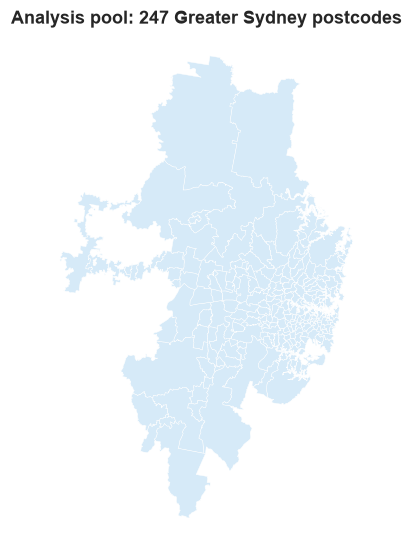

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 6))
p = poa_nsw[poa_nsw.poa.isin(POOL)]
p.plot(ax=ax, color="#d6eaf8", edgecolor="white", linewidth=0.3)
ax.set_aspect(1 / np.cos(np.radians(33.85)))
ax.set_axis_off(); ax.set_title(f"Analysis pool: {len(p)} Greater Sydney postcodes")
plt.show()

# 6. Source E – NSW DCJ Rent tables, 2018–2022 (enrichment)

## What it is
The Department of Communities and Justice publishes a quarterly Rent and Sales Report built from the **same bond lodgements** as Source A, but already
summarised: for each **postcode × dwelling type × number of bedrooms**, the 25th percentile, median and 75th percentile weekly rent of new bonds,
the number of new bonds and the number of bonds held.

- **One row =** one postcode × dwelling type × bedroom group × quarter.
- **Why it is useful:** it exists for **2019 and 2020**, the years missing from Source A, and it can be checked against Source A in the years they overlap.
- **Cells with 10 or fewer new bonds are hidden.**

## Extract

In [20]:
DCJ_PAGE = "https://dcj.nsw.gov.au/about-us/families-and-communities-statistics/housing-rent-and-sales/previous-rent-and-sales-reports.html"
DCJ_FIRST, DCJ_LAST = 2018, 2022
QMAP = {"march": 1, "june": 2, "september": 3, "december": 4}
soup = BeautifulSoup(get_text(DCJ_PAGE), "html.parser")
dcj_links = {}
for a in soup.find_all("a", href=True):
    mm = re.search(r"issue-(\d+)-rent-tables-(march|june|september|december)-(\d{4})", a["href"])
    if mm and DCJ_FIRST <= int(mm.group(3)) <= DCJ_LAST:
        dcj_links[(int(mm.group(3)), QMAP[mm.group(2)])] = ("https://dcj.nsw.gov.au" + a["href"]) if a["href"].startswith("/") else a["href"]
print(f"Quarterly rent workbooks found: {len(dcj_links)} ({min(dcj_links)} to {max(dcj_links)})")

parts = []
for (yr, q), url in sorted(dcj_links.items()):
    fp = fetch(url, RAW / "dcj_rent" / url.rsplit("/", 1)[1])
    d = pd.read_excel(fp, sheet_name="Postcode", header=5, dtype=str)
    d = d.iloc[:, :8]
    d.columns = ["postcode", "dwelling_type", "bedrooms", "rent_q1", "rent_median", "rent_q3", "new_bonds", "bonds_held"]
    d["quarter"] = f"{yr}Q{q}"
    parts.append(d)
dcj_raw = pd.concat(parts, ignore_index=True)
dcj = dcj_raw.copy()
for c in ["rent_q1", "rent_median", "rent_q3", "new_bonds", "bonds_held"]:
    dcj[c + "_flag"] = np.where(pd.to_numeric(dcj[c], errors="coerce").isna(), dcj[c], "")          # keeps '-' (hidden) markers
    dcj[c] = pd.to_numeric(dcj[c], errors="coerce")
dcj["postcode"] = pd.to_numeric(dcj["postcode"], errors="coerce")
dcj = dcj.dropna(subset=["postcode"]).assign(postcode=lambda d: d.postcode.astype(int).astype(str).str.zfill(4)).rename(columns={"postcode": "poa"})
check("dcj: quarters", dcj.quarter.nunique(), 20)
check("dcj: rows", len(dcj), 328_021, tol=5_000)
register("dcj_rent_postcode_quarterly", dcj, "dcj_rent_postcode_quarterly.parquet", "one postcode × dwelling type × bedrooms × quarter", "Enrichment",
         "Pre-COVID check; fills 2019–2020", "poa; quarter", "Mar 2018 – Dec 2022 quarters")

Quarterly rent workbooks found: 20 ((2018, 1) to (2022, 4))


## Overview

In [21]:
display(card(dcj, "dcj_rent_postcode_quarterly"))
dcj[(dcj.poa == "2007") & (dcj.dwelling_type == "Flat/Unit") & dcj.bedrooms.isin(["1 Bedroom", "2 Bedrooms"])].sort_values(["bedrooms", "quarter"]).head(6)

dcj_rent_postcode_quarterly: 328,021 rows × 14 columns | 49.7 MB in memory


,type,missing %,distinct,example
poa,str,0.00,659,2000
dwelling_type,str,0.00,5,Total
bedrooms,str,0.00,7,1 Bedroom
rent_q1,float64,74.70,1649,469.00
rent_median,float64,74.70,1046,609.00
rent_q3,float64,74.70,2031,725.00
new_bonds,float64,87.00,924,611.00
bonds_held,float64,53.60,4906,"3,045.00"
quarter,str,0.00,20,2018Q1
rent_q1_flag,str,0.00,2,


,poa,dwelling_type,bedrooms,rent_q1,rent_median,rent_q3,new_bonds,bonds_held,quarter,rent_q1_flag,rent_median_flag,rent_q3_flag,new_bonds_flag,bonds_held_flag
59,2007,Flat/Unit,1 Bedroom,550.00,590.00,617.50,82.00,603.00,2018Q1,,,,,
16484,2007,Flat/Unit,1 Bedroom,530.00,560.00,620.00,55.00,604.00,2018Q2,,,,,
32940,2007,Flat/Unit,1 Bedroom,540.00,567.50,620.00,74.00,626.00,2018Q3,,,,,
49394,2007,Flat/Unit,1 Bedroom,500.00,560.00,585.00,81.00,638.00,2018Q4,,,,,
65862,2007,Flat/Unit,1 Bedroom,459.00,550.00,600.00,134.00,698.00,2019Q1,,,,,
82331,2007,Flat/Unit,1 Bedroom,538.00,560.00,588.00,55.00,687.00,2019Q2,,,,,


## Data dictionary

| Column | Meaning |
|---|---|
| `poa` | Postcode (text) |
| `dwelling_type` | `Flat/Unit`, `House`, `Townhouse`, `Other`, `Total` |
| `bedrooms` | `Bedsitter`, `1 Bedroom`, `2 Bedrooms`, `3 Bedrooms`, `4 or more Bedrooms`, `Not Specified`, `Total` |
| `rent_q1`, `rent_median`, `rent_q3` | 25th percentile, median and 75th percentile weekly rent of new bonds (AUD) |
| `new_bonds`, `bonds_held` | New bonds lodged in the quarter; bonds currently held |
| `*_flag` | `-` where the value is hidden because 10 or fewer bonds |
| `quarter` | Calendar quarter, for example `2019Q4` |

## Quality notes

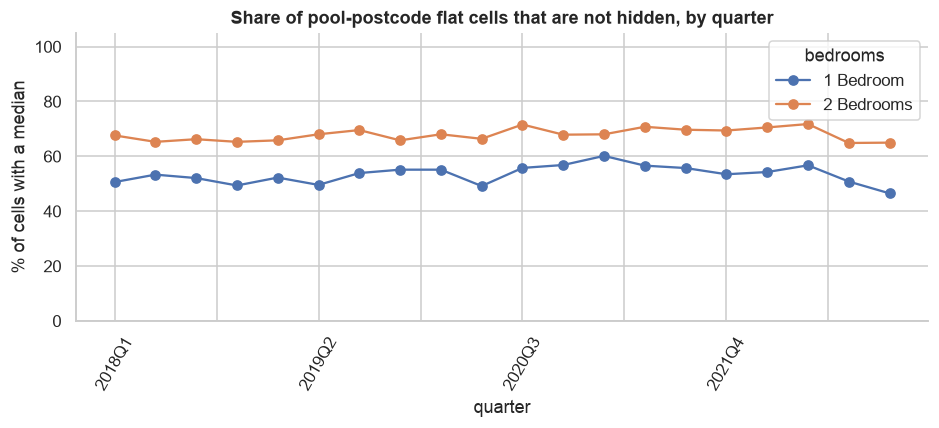

Hidden medians overall: 75% | flats with 1–2 bedrooms in the 247 pool postcodes: 39%
Pool postcodes where a flat median is shown in every quarter: 94 of 246 | hidden in more than half the quarters: 98


Flat-heavy pool postcodes: 138 | median shown in every quarter: 91 | shown in at least 80% of quarters: 115 | hidden in more than half: 9


In [22]:
flat = dcj[(dcj.dwelling_type == "Flat/Unit") & dcj.bedrooms.isin(["1 Bedroom", "2 Bedrooms"]) & dcj.poa.isin(POOL)]
avail = flat.assign(has=flat.rent_median.notna()).groupby(["quarter", "bedrooms"]).has.mean().unstack() * 100
fig, ax = plt.subplots(figsize=(10, 3.4))
avail.plot(ax=ax, marker="o")
ax.set_ylim(0, 105); ax.set_ylabel("% of cells with a median")
ax.set_title("Share of pool-postcode flat cells that are not hidden, by quarter")
plt.xticks(rotation=60); plt.show()
print("Hidden medians overall:", f"{dcj.rent_median.isna().mean():.0%}", "| flats with 1–2 bedrooms in the 247 pool postcodes:", f"{flat.rent_median.isna().mean():.0%}")
hid = flat.assign(hidden=flat.rent_median.isna()).groupby("poa").hidden.mean()
print(f"Pool postcodes where a flat median is shown in every quarter: {(hid == 0).sum()} of {len(hid)} | hidden in more than half the quarters: {(hid > 0.5).sum()}")
# Same question for flat-heavy postcodes (at least 35% of 2018 bonds were flats), which are the ones the project compares.
b18_pool = bond[(bond.period_source.str.startswith("2018")) & bond.postcode.astype(str).str.zfill(4).isin(POOL)]
flat_share = b18_pool.assign(poa=b18_pool.postcode.astype(str).str.zfill(4)).groupby("poa").dwelling_type.apply(lambda s: (s == "F").mean())
heavy = flat_share[flat_share >= 0.35].index
hid_h = hid.reindex(heavy).dropna()
print(f"Flat-heavy pool postcodes: {len(hid_h)} | median shown in every quarter: {(hid_h == 0).sum()} | shown in at least 80% of quarters: {(hid_h <= 0.2).sum()} | hidden in more than half: {(hid_h > 0.5).sum()}")

- **Most cells are hidden overall** (small postcodes, rare dwelling types). Hidden cells are concentrated in outer, house-dominated postcodes where flats are rare;
  the counts above show how much better the coverage is for flat-heavy postcodes, which are the ones the project compares.
- These are **summaries**: they cannot be recombined (for example, "Bedsitter" and "1 Bedroom" cannot be merged into one median).
- Rents agree closely with Source A in the quarters both cover (see the cross-check in section 12).

## Role in the project
Fills **2019–2020** so the project can test whether near-campus and far-from-campus postcodes were already moving differently before COVID.

# 7. Source F – ABS Census 2021: postcode tables (enrichment)

## What it is
The Census counts everyone on Census night (10 Aug 2021). The "General Community Profile" DataPacks publish ready-made tables by postcode.
Four tables are extracted:

| Table | Title | Used for |
|---|---|---|
| G01 | Selected person characteristics | Total residents (the denominator) |
| G02 | Selected medians and averages | Median weekly rent, median household income |
| G15 | Type of educational institution attending | **Residents attending university** (the second exposure measure) |
| G37 | Tenure and landlord type by dwelling structure | Share of homes that are rented |

**Caution.** G15 counts **all** university students (domestic and international). The 2021 Census was taken while borders were closed, so international
students are under-represented.

## Extract

In [23]:
cen_zip = fetch("https://www.abs.gov.au/census/find-census-data/datapacks/download/2021_GCP_POA_for_NSW_short-header.zip",
                RAW / "abs_census" / "2021_GCP_POA_for_NSW_short-header.zip")
def read_census(table: str) -> pd.DataFrame:
    with zipfile.ZipFile(cen_zip) as z:
        name = [n for n in z.namelist() if n.endswith(f"2021Census_{table}_NSW_POA.csv")][0]
        d = pd.read_csv(z.open(name))
    d.insert(0, "poa", d["POA_CODE_2021"].str.replace("POA", "").str.zfill(4))
    return d.drop(columns="POA_CODE_2021")
g01, g02, g15, g37 = (read_census(t) for t in ["G01", "G02", "G15", "G37"])
with zipfile.ZipFile(cen_zip) as z:
    meta = pd.read_excel(io.BytesIO(z.read("Metadata/Metadata_2021_GCP_DataPack_R1_R2.xlsx")), sheet_name=0, header=None)
print({t: d.shape for t, d in zip(["G01", "G02", "G15", "G37"], [g01, g02, g15, g37])})
display(meta[meta[0].isin(["G01", "G02", "G15", "G37"])].rename(columns={0: "table", 1: "title", 2: "population counted"}))

{'G01': (612, 109), 'G02': (612, 9), 'G15': (612, 85), 'G37': (612, 73)}


,table,title,population counted
9,G01,Selected Person Characteristics by Sex,Persons
10,G02,Selected Medians and Averages,NaN
23,G15,Type of Educational Institution Attending (Ful...,Persons attending an educational institution
45,G37,Tenure and Landlord Type by Dwelling Structure,Occupied private dwellings


In [24]:
rent_cols = [c for c in g37.columns if c.startswith("R_") and c.endswith("_Total")]
UNI = "Tert_Uni_other_high_edu_Tot_P"
census = (g01[["poa", "Tot_P_P"]].rename(columns={"Tot_P_P": "residents"})
          .merge(g15[["poa", UNI, "Tert_Uni_oth_h_edu_Ft_15_24_P"]].rename(columns={UNI: "uni_students", "Tert_Uni_oth_h_edu_Ft_15_24_P": "uni_students_ft_15_24"}), on="poa")
          .merge(g02[["poa", "Median_rent_weekly", "Median_tot_hhd_inc_weekly", "Median_age_persons"]]
                 .rename(columns={"Median_rent_weekly": "median_rent_weekly", "Median_tot_hhd_inc_weekly": "median_hhd_income_weekly", "Median_age_persons": "median_age"}), on="poa")
          .merge(pd.DataFrame({"poa": g37.poa, "renting_households": g37[rent_cols].sum(axis=1), "owning_households": g37["O_OR_Total"] + g37["O_MTG_Total"]}), on="poa"))
census["uni_students_per_100"] = 100 * census.uni_students / census.residents
census["uni_ft_15_24_per_100"] = 100 * census.uni_students_ft_15_24 / census.residents
census["renter_share_pct"] = 100 * census.renting_households / (census.renting_households + census.owning_households)
check("census: NSW postcodes", len(census), 612)
check("census: pool postcodes found", int(census.poa.isin(POOL).sum()), 247)
register("census2021_postcode", census, "census2021_postcode.parquet", "one NSW postcode area", "Enrichment",
         "Residents who are university students; renter share; medians", "poa", "Census night, 10 Aug 2021")

## Overview

In [25]:
display(card(census, "census2021_postcode"))
census[census.poa.isin(["2008", "2050", "2007", "2134", "2135"])].round(1)

census2021_postcode: 612 rows × 12 columns | 0.1 MB in memory


,type,missing %,distinct,example
poa,str,0.00,612,2000
residents,int64,0.00,603,27936
uni_students,int64,0.00,421,2599
uni_students_ft_15_24,int64,0.00,336,1249
median_rent_weekly,int64,0.00,147,625
median_hhd_income_weekly,int64,0.00,519,2225
median_age,int64,0.00,38,32
renting_households,int64,0.00,549,16353
owning_households,int64,0.00,572,2884
uni_students_per_100,float64,0.00,601,9.30


,poa,residents,uni_students,uni_students_ft_15_24,median_rent_weekly,median_hhd_income_weekly,median_age,renting_households,owning_households,uni_students_per_100,uni_ft_15_24_per_100,renter_share_pct
1,2007,7410,1493,830,500,1805,30,3984,722,20.10,11.20,84.70
2,2008,10400,2989,1933,525,1746,28,6658,1118,28.70,18.60,85.60
41,2050,9381,1989,1256,570,2331,33,4948,1519,21.20,13.40,76.50
109,2134,18224,2236,1356,500,1671,32,7936,2477,12.30,7.40,76.20
110,2135,25915,3077,1815,480,2262,32,7540,4493,11.90,7.00,62.70


## Data dictionary

| Column | Source table | Meaning |
|---|---|---|
| `residents` | G01 | Usual residents counted |
| `uni_students` | G15 | Residents attending university or another higher-education institution (all ages, full and part time) |
| `uni_students_ft_15_24` | G15 | Of those, full-time and aged 15–24 |
| `median_rent_weekly`, `median_hhd_income_weekly`, `median_age` | G02 | Medians for the postcode |
| `renting_households`, `owning_households` | G37 | Occupied private dwellings rented, or owned (outright or with a mortgage) |
| `uni_students_per_100`, `uni_ft_15_24_per_100`, `renter_share_pct` | derived | Rates used for comparison |

## Quality notes

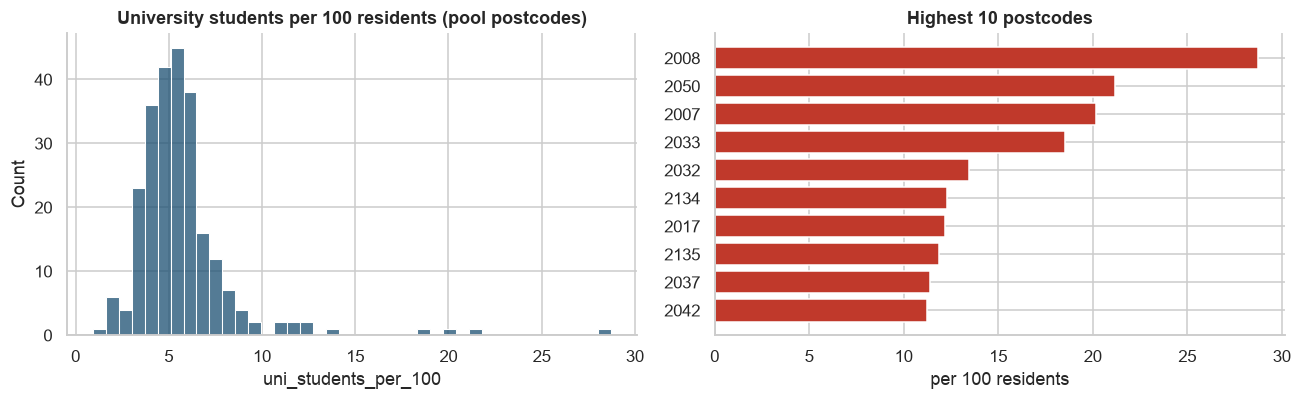

Pool postcodes with fewer than 2,000 residents (rates are noisy): 13


In [26]:
pool_c = census[census.poa.isin(POOL)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(pool_c.uni_students_per_100, bins=40, ax=axes[0], color="#1b4f72")
axes[0].set_title("University students per 100 residents (pool postcodes)")
top = pool_c.sort_values("uni_students_per_100", ascending=False).head(10)
axes[1].barh(top.poa[::-1], top.uni_students_per_100[::-1], color="#c0392b"); axes[1].set_title("Highest 10 postcodes"); axes[1].set_xlabel("per 100 residents")
plt.tight_layout(); plt.show()
print("Pool postcodes with fewer than 2,000 residents (rates are noisy):", int((pool_c.residents < 2000).sum()))

- Counts include domestic students; "overseas-born" is not the same as "international student".
- Census 2021 happened during border restrictions, so it shows the **domestic and resident** student population more than the international one.
- Postcode areas with few residents give unstable rates.
- Other tables (for example G33 household income by composition and G40 rent by landlord type) are available in the same DataPack but are **not extracted** because
  the project does not use them.

## Role in the project
A **second, independent exposure measure** (where university students actually live) to check the campus-based one, plus the rented-home share and medians for describing the groups.

# 8. Source G – Home Affairs BP0019: student visa holders in Australia (enrichment)

## What it is
BP0019 counts **temporary visa holders who are present in Australia** at the end of each quarter (a *stock*), unlike BP0015, which counts visas
*granted* (a *flow*). It is published as an Excel pivot table; the full detail sits in the pivot's hidden data, which is read directly here.

- **One row =** snapshot date × visa category × subclass × applicant type × citizenship.
- **National only:** there is **no state or postcode** in the data.
- **Why it is useful:** number of students *present* is the better indicator of demand than visas granted, and the series shows the seasonal rhythm of student presence.

## Extract

In [27]:
bp_res = [r for r in ckan_resources(CKAN, "temporary-entrants-visa-holders") if r.get("format", "").upper() == "XLSX" and r["name"].startswith("BP0019")]
bp_res = sorted(bp_res, key=lambda r: r.get("last_modified") or "", reverse=True)[0]
bp_fp = fetch(bp_res["url"], RAW / "bp0019" / "bp0019_latest.xlsx")
print("Using:", bp_res["name"])

def read_pivot_cache(xlsx: Path) -> pd.DataFrame:
    """Read the records stored behind an Excel pivot table (the sheet only shows a summary)."""
    ns = {"m": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    with zipfile.ZipFile(xlsx) as z:
        root = ET.fromstring(z.read("xl/pivotCache/pivotCacheDefinition1.xml"))
        names, shared = [], []
        for cf in root.find("m:cacheFields", ns):
            names.append(cf.attrib["name"])
            si = cf.find("m:sharedItems", ns)
            shared.append([it.attrib.get("v") for it in list(si)] if si is not None else [])
        rows = []
        with z.open("xl/pivotCache/pivotCacheRecords1.xml") as fh:
            for _, el in ET.iterparse(fh, events=("end",)):
                if el.tag.endswith("}r"):
                    rec = []
                    for i, c in enumerate(list(el)):
                        if c.tag.endswith("}x"):
                            idx = int(c.attrib["v"]); rec.append(shared[i][idx] if idx < len(shared[i]) else None)
                        else:
                            rec.append(c.attrib.get("v"))
                    rows.append(rec); el.clear()
    return pd.DataFrame(rows, columns=names)

bp = read_pivot_cache(bp_fp)
bp = bp.rename(columns={"Snapshot Date": "snapshot", "Visa Category": "visa_category", "Visa Subclass": "visa_subclass", "Visa Type": "visa_type",
                        "Applicant Type": "applicant_type", "Citizenship Country": "citizenship", "Visa Holders": "visa_holders"})
bp["snapshot"] = pd.to_datetime(bp["snapshot"]).dt.date.astype("datetime64[ns]")
bp["visa_holders"] = pd.to_numeric(bp["visa_holders"])
check("bp0019: snapshots", bp.snapshot.nunique(), 60, tol=2)
check("bp0019: records", len(bp), 308_631, tol=20_000)
register("bp0019_visa_holders", bp, "bp0019_visa_holders.parquet", "one snapshot × visa subclass × applicant type × citizenship", "Enrichment",
         "Students present (stock): phases and seasonality", "snapshot date (national)", "Dec 2011 – Sep 2026, quarterly")

Using: BP0019 Number of Temporary visa holders in Australia at 2026-09-30


## Overview

In [28]:
display(card(bp, "bp0019_visa_holders"))
bp[bp.visa_category == "Student"].head(5)

bp0019_visa_holders: 308,631 rows × 7 columns | 42.8 MB in memory


,type,missing %,distinct,example
snapshot,datetime64[ns],0.00,60,2011-12-31 00:00:00
visa_category,str,0.00,11,Bridging
visa_subclass,str,0.00,66,Bridging Visas
visa_type,str,0.00,60,Bridging
applicant_type,str,0.00,2,Primary
citizenship,str,0.00,236,Afghanistan
visa_holders,int64,0.00,7352,6


,snapshot,visa_category,visa_subclass,visa_type,applicant_type,citizenship,visa_holders
534,2011-12-31,Student,560 Student,Higher Education Sector,Primary,Malaysia,1
535,2011-12-31,Student,560 Student,Higher Education Sector,Primary,Sri Lanka,1
536,2011-12-31,Student,560 Student,Higher Education Sector,Secondary,Ghana,2
537,2011-12-31,Student,560 Student,Higher Education Sector,Secondary,Not Specified,1
538,2011-12-31,Student,560 Student,Schools Sector,Primary,Not Specified,1


## Data dictionary

| Column | Meaning |
|---|---|
| `snapshot` | Quarter-end date the stock is counted at |
| `visa_category` | Student, Temporary Graduate, Visitor, Working Holiday Maker, … |
| `visa_subclass`, `visa_type` | Specific visa (for example "500 Student") |
| `applicant_type` | `Primary` (the student) or `Secondary` (family member) |
| `citizenship` | Country of citizenship |
| `visa_holders` | Number of visa holders present at the snapshot |

## Quality notes

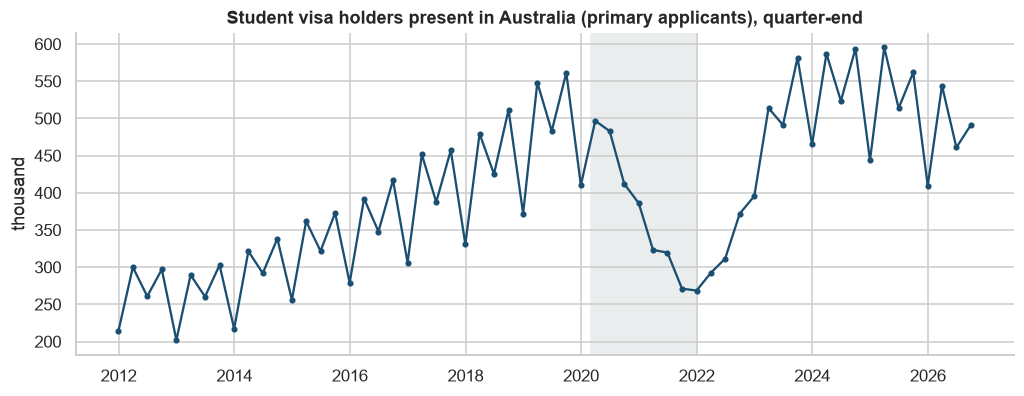

Trough Dec 2021: 268,529 | Peak Mar 2025: 595,339 | Latest Sep 2026: 491,361
Average level by quarter-end month since 2022 (thousand): {3: 506.0, 6: 460.0, 9: 520.0, 12: 428.0}


In [29]:
stu = (bp[(bp.visa_category == "Student") & (bp.applicant_type == "Primary")].groupby("snapshot").visa_holders.sum().sort_index())
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(stu.index, stu.values / 1000, color="#1b4f72", marker="o", ms=3)
ax.set_title("Student visa holders present in Australia (primary applicants), quarter-end"); ax.set_ylabel("thousand")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="#eaeded", zorder=0)
plt.show()
rec = stu["2019-01-01":]
print(f"Trough {rec.idxmin():%b %Y}: {rec.min():,.0f} | Peak {rec.idxmax():%b %Y}: {rec.max():,.0f} | Latest {rec.index[-1]:%b %Y}: {rec.iloc[-1]:,.0f}")
q_pat = stu["2022-01-01":].groupby(stu["2022-01-01":].index.month).mean().round(0)
print("Average level by quarter-end month since 2022 (thousand):", (q_pat / 1000).round(0).to_dict())

- The stock is **national**; NSW cannot be separated, so it is used to define phases and seasonality, not as a regional measure.
- The series is strongly seasonal: higher at the end of March and September, lower at the end of June and December.
- The stock peaks in **March 2025**, later than the flow of visas granted (peak mid-2023); courses last years, so presence lags new visas.

## Role in the project
Replaces visas *granted* as the indicator for **phases** (trough, recovery, plateau, decline) and gives evidence for the **seasonal rhythm** of student presence.

# 9. Source H – City of Sydney Housing Audit, 2015–2025 (enrichment)

## What it is
The City of Sydney counts every dwelling in its area each June. The report separates **private dwellings** from **non-private dwellings**
(boarding house rooms, student accommodation rooms, residential care). The student-room figure is stated in the text of each PDF report.

- **One row =** one June audit year for the City of Sydney local area.
- **Only the City of Sydney**, not other councils. The PDF tables by "village" mix student rooms with other non-private dwellings, so only the totals are extracted.

## Extract

In [30]:
COS_PAGE = "https://www.cityofsydney.nsw.gov.au/research-reports/city-monitor-reports"
audit_links = {}
for a in BeautifulSoup(get_text(COS_PAGE), "html.parser").find_all("a", href=True):
    mm = re.search(r"housing-audit[^/]*?(\d{4})\.pdf", a["href"])
    if mm:
        audit_links[int(mm.group(1))] = a["href"] if a["href"].startswith("http") else "https://www.cityofsydney.nsw.gov.au" + a["href"]
print("Audit years found:", sorted(audit_links))

import pymupdf
PAT = re.compile(r"([\d,]+) non-private dwellings in the City of Sydney local area, including ([\d,]+) boarding house rooms.*?"
                 r"([\d,]+) student accommodation rooms.*?(?:and|,) ([\d,]+) other", re.S)
rows = []
for yr, url in sorted(audit_links.items()):
    fp = fetch(url, RAW / "cos_housing_audit" / f"housing-audit-june-{yr}.pdf")
    text = re.sub(r"\s+", " ", "\n".join(p.get_text() for p in pymupdf.open(fp)))
    m = PAT.search(text)
    if m:
        total, boarding, student, other = (int(x.replace(",", "")) for x in m.groups())
        rows.append({"audit_year": yr, "non_private_total": total, "boarding_house_rooms": boarding, "student_rooms": student, "other_non_private": other,
                     "source_pdf": fp.name})
    else:
        print("  could not read the room counts in", fp.name)
audit = pd.DataFrame(rows).sort_values("audit_year").reset_index(drop=True)
audit["student_rooms_net_change"] = audit.student_rooms.diff()
check("audit: years extracted", len(audit), 11)
check("audit: student rooms June 2025", int(audit.loc[audit.audit_year == 2025, "student_rooms"].iloc[0]) if (audit.audit_year == 2025).any() else None, 12_924)
register("cos_housing_audit_student_rooms", audit, "cos_housing_audit_student_rooms.csv", "one June audit (City of Sydney local area)", "Enrichment",
         "Supply of student rooms (context)", "audit_year (City of Sydney only)", "June 2015 – June 2025")

Audit years found: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


## Overview

In [31]:
display(audit)

,audit_year,non_private_total,boarding_house_rooms,student_rooms,other_non_private,source_pdf,student_rooms_net_change
0,2015,10391,2853,6797,741,housing-audit-june-2015.pdf,NaN
1,2016,11569,3205,7624,740,housing-audit-june-2016.pdf,827.00
2,2017,12976,3154,9101,721,housing-audit-june-2017.pdf,"1,477.00"
3,2018,13187,3212,9352,623,housing-audit-june-2018.pdf,251.00
4,2019,14444,3310,10537,642,housing-audit-june-2019.pdf,"1,185.00"
5,2020,14657,3350,10688,639,housing-audit-june-2020.pdf,151.00
6,2021,15127,3551,10937,639,housing-audit-june-2021.pdf,249.00
7,2022,15740,3572,11529,639,housing-audit-june-2022.pdf,592.00
8,2023,15861,3508,11714,639,housing-audit-june-2023.pdf,185.00
9,2024,16366,3482,12120,764,housing-audit-june-2024.pdf,406.00


## Data dictionary

| Column | Meaning |
|---|---|
| `audit_year` | The June of the audit |
| `non_private_total` | All non-private dwellings: boarding house rooms, student accommodation rooms, other |
| `boarding_house_rooms`, `student_rooms`, `other_non_private` | Components of the total |
| `student_rooms_net_change` | Change in student rooms since the previous audit |

## Quality notes

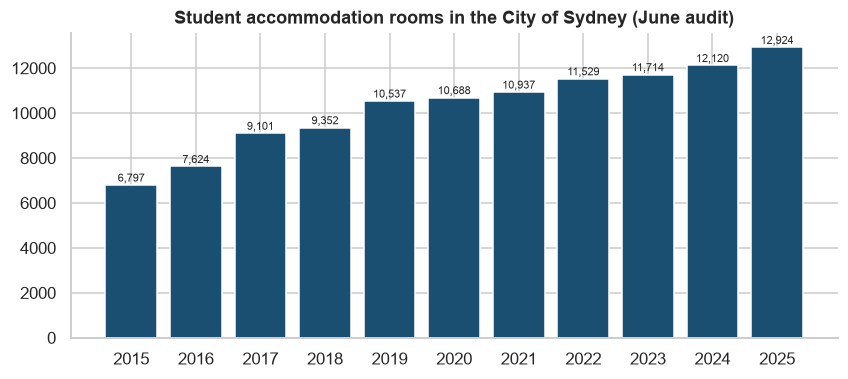

In [32]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(audit.audit_year, audit.student_rooms, color="#1b4f72")
for x, v in zip(audit.audit_year, audit.student_rooms):
    ax.text(x, v + 150, f"{v:,}", ha="center", fontsize=7)
ax.set_title("Student accommodation rooms in the City of Sydney (June audit)"); ax.set_xticks(audit.audit_year)
plt.show()

- The counts are pulled from sentences in the PDFs with a pattern; the check above compares the 2025 figure (12,924) with the report. If the City changes the wording, the
  pattern needs updating.
- **City of Sydney only.** There is no postcode split of student rooms in the audit.
- The 2025 report adds "co-living" units to the boarding-house description, so the boarding-house series is not perfectly comparable over time.

## Role in the project
A short **supply context** series for the end user's own area: how many student rooms the City has added each year.

# 10. How the tables connect

The postcode (`poa`) is the main thread. Students are counted by SA4, phases by date, and supply by year.

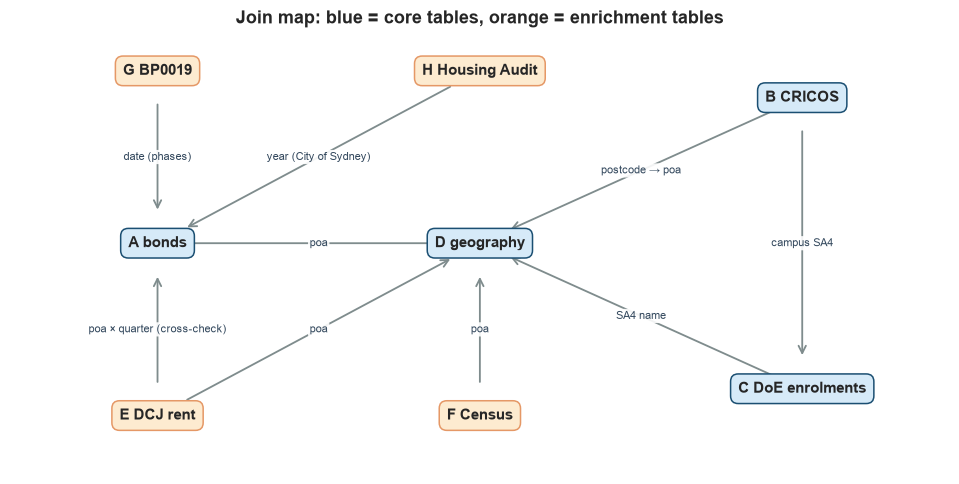

In [33]:
edges = [("A bonds", "D geography", "poa"), ("E DCJ rent", "D geography", "poa"), ("F Census", "D geography", "poa"),
         ("B CRICOS", "D geography", "postcode → poa"), ("C DoE enrolments", "D geography", "SA4 name"),
         ("B CRICOS", "C DoE enrolments", "campus SA4"), ("E DCJ rent", "A bonds", "poa × quarter (cross-check)"),
         ("G BP0019", "A bonds", "date (phases)"), ("H Housing Audit", "A bonds", "year (City of Sydney)")]
pos = {"A bonds": (0.0, 0.5), "D geography": (0.55, 0.5), "B CRICOS": (1.1, 0.88), "C DoE enrolments": (1.1, 0.12),
       "E DCJ rent": (0.0, 0.05), "F Census": (0.55, 0.05), "G BP0019": (0.0, 0.95), "H Housing Audit": (0.55, 0.95)}
core = {"A bonds", "B CRICOS", "C DoE enrolments", "D geography"}
fig, ax = plt.subplots(figsize=(11, 5.2))
for a, b, label in edges:
    (x1, y1), (x2, y2) = pos[a], pos[b]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#7f8c8d", lw=1.2, shrinkA=22, shrinkB=22))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, label, ha="center", va="center", fontsize=7.5, color="#34495e",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
for n, (x, y) in pos.items():
    ax.text(x, y, n, ha="center", va="center", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", fc="#d6eaf8" if n in core else "#fdebd0", ec="#1b4f72" if n in core else "#e59866"))
ax.set_xlim(-0.25, 1.35); ax.set_ylim(-0.1, 1.05); ax.axis("off")
ax.set_title("Join map: blue = core tables, orange = enrichment tables")
plt.show()

## Coverage in time
Each table covers a different period. Only the bond table has a gap (2019–2020), which the DCJ table fills.

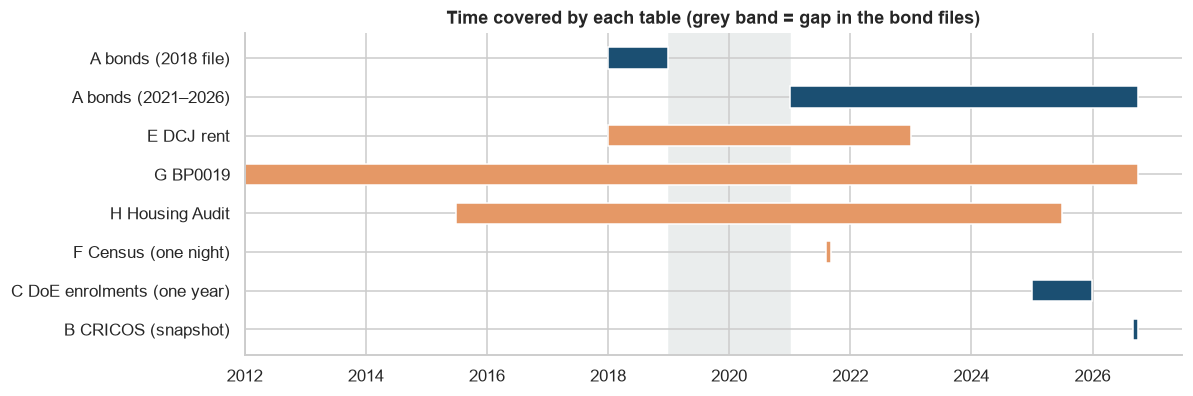

In [34]:
cov = pd.DataFrame([
    ("A bonds (2018 file)", "2018-01-01", "2018-12-31"), ("A bonds (2021–2026)", "2021-01-01", "2026-09-30"),
    ("E DCJ rent", "2018-01-01", "2022-12-31"), ("G BP0019", "2011-12-31", "2026-09-30"),
    ("H Housing Audit", "2015-06-30", "2025-06-30"), ("F Census (one night)", "2021-08-10", "2021-08-10"),
    ("C DoE enrolments (one year)", "2025-01-01", "2025-12-31"), ("B CRICOS (snapshot)", "2026-09-01", "2026-09-30")],
    columns=["table", "start", "end"])
cov[["start", "end"]] = cov[["start", "end"]].apply(pd.to_datetime)
fig, ax = plt.subplots(figsize=(11, 3.8))
for i, r in enumerate(cov.itertuples()):
    ax.barh(i, max((r.end - r.start).days, 25), left=r.start, color="#1b4f72" if r.table[0] in "ABCD" else "#e59866", height=0.55)
ax.set_yticks(range(len(cov))); ax.set_yticklabels(cov.table); ax.invert_yaxis()
ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2020-12-31"), color="#eaeded", zorder=0)
ax.set_title("Time covered by each table (grey band = gap in the bond files)")
plt.show()

## Postcode coverage across the tables
For the 247 pool postcodes: does each table have something to say about it?

In [35]:
rent_pc = set(bond.postcode.astype(str).str.zfill(4))
dcj_flat = dcj[(dcj.dwelling_type == "Flat/Unit") & dcj.bedrooms.isin(["1 Bedroom", "2 Bedrooms"]) & dcj.rent_median.notna()]
campus_pc = set(cricos_cl.loc[(cricos_cl.state == "NSW") & cricos_cl.postcode.notna(), "postcode"])
campus_pc = {"2033" if p == "2052" else "2113" if p == "2109" else p for p in campus_pc}
cover = pd.DataFrame({"poa": POOL})
cover["A bonds"] = cover.poa.isin(rent_pc)
cover["D centre point"] = cover.poa.isin(poa_centres.poa)
cover["E DCJ flat median"] = cover.poa.isin(dcj_flat.poa)
cover["F Census"] = cover.poa.isin(census.poa)
cover["B has a CRICOS location (any level)"] = cover.poa.isin(campus_pc)
summary = pd.DataFrame({"postcodes covered": cover.drop(columns="poa").sum(), "of": len(cover)})
summary["%"] = (summary["postcodes covered"] / summary.of * 100).round(0)
display(summary)

,postcodes covered,of,%
A bonds,247,247,100.00
D centre point,247,247,100.00
E DCJ flat median,187,247,76.00
F Census,247,247,100.00
B has a CRICOS location (any level),124,247,50.00


# 11. Cross-check: DCJ summaries against the bond rows
Source E is built from the same bonds as Source A. Where both exist (2018 and 2021–2022), the quarterly medians should agree. A good match means the two can be
used together, and that DCJ can stand in for the missing 2019–2020 bond rows.

In [36]:
mine = (bond[(bond.dwelling_type == "F") & bond.bedrooms.isin([1, 2]) & bond.weekly_rent.notna()]
        .assign(poa=lambda d: d.postcode.astype(str).str.zfill(4), quarter=lambda d: d.lodgement_date.dt.to_period("Q").astype(str),
                bedrooms=lambda d: d.bedrooms.map({1: "1 Bedroom", 2: "2 Bedrooms"}))
        .groupby(["poa", "quarter", "bedrooms"]).weekly_rent.agg(own_median="median", own_bonds="size").reset_index())
cmp_ = (dcj[(dcj.dwelling_type == "Flat/Unit") & dcj.bedrooms.isin(["1 Bedroom", "2 Bedrooms"])]
        .merge(mine, on=["poa", "quarter", "bedrooms"]).dropna(subset=["rent_median", "own_median"]))
cmp_ = cmp_[cmp_.poa.isin(POOL)]
cmp_["diff"] = cmp_.own_median - cmp_.rent_median
res = pd.Series({"overlapping cells": len(cmp_), "correlation": np.corrcoef(cmp_.own_median, cmp_.rent_median)[0, 1],
                 "share identical %": (cmp_["diff"] == 0).mean() * 100, "share within $10 %": (cmp_["diff"].abs() <= 10).mean() * 100,
                 "median bonds ratio (own ÷ DCJ)": (cmp_.own_bonds / cmp_.new_bonds).median()})
display(res.round(3).to_frame("value"))
check("cross-check: correlation (pool postcodes, flats 1–2 bedrooms)", round(float(res["correlation"]), 2), 1.0, tol=0.02)

,value
overlapping cells,"3,522.00"
correlation,1.00
share identical %,64.91
share within $10 %,91.51
median bonds ratio (own ÷ DCJ),1.03


# 12. Catalogue of the extracted tables
One line per extracted table. This is the list to keep open while editing the project notebook.

In [37]:
catalogue = pd.DataFrame(REGISTRY)
catalogue.to_csv(OUT / "data_catalogue.csv", index=False)
catalogue.drop(columns=["file"]).rename(columns={"size_MB": "MB"})

,table,one row is,rows,columns,MB,group,role,join keys,period
0,bond_lodgements,one bond lodged (one new tenancy),2215281,7,6.51,Core,Outcome: new-lease weekly rent,postcode (→ ABS POA); lodgement_date,2018; Jan 2021 – Sep 2026
1,cricos_course_locations,one course offered at one location,46511,16,0.94,Core,Campus locations and course level,postcode (→ ABS POA); cricos_provider_code,"Snapshot, Sep 2026"
2,doe_enrolments_sa4,one SA4 × sector × field of study,1135,8,0.02,Core,Where international students study (shares bet...,sa4_name (→ ABS SA4 names),Year to Dec 2025
3,abs_postcode_correspondence,one postcode × one region it overlaps (with po...,13268,6,0.11,Core,"Maps postcodes to SA4, SA3, LGA and Greater Sy...",poa,ASGS Edition 3 (2021)
4,abs_postcode_centres,one NSW postcode area (centre point),636,4,0.02,Core,Distances and maps,poa,ASGS Edition 3 (2021)
5,dcj_rent_postcode_quarterly,one postcode × dwelling type × bedrooms × quarter,328021,14,1.32,Enrichment,Pre-COVID check; fills 2019–2020,poa; quarter,Mar 2018 – Dec 2022 quarters
6,census2021_postcode,one NSW postcode area,612,12,0.05,Enrichment,Residents who are university students; renter ...,poa,"Census night, 10 Aug 2021"
7,bp0019_visa_holders,one snapshot × visa subclass × applicant type ...,308631,7,0.69,Enrichment,Students present (stock): phases and seasonality,snapshot date (national),"Dec 2011 – Sep 2026, quarterly"
8,cos_housing_audit_student_rooms,one June audit (City of Sydney local area),11,7,0.00,Enrichment,Supply of student rooms (context),audit_year (City of Sydney only),June 2015 – June 2025


In [38]:
display(pd.DataFrame(CHECKS))
failed = [c for c in CHECKS if c["ok"].startswith("✗")]
print(f"{len(CHECKS) - len(failed)} of {len(CHECKS)} checks match the values seen when the sources were first inspected.")

,check,found,expected,ok
0,bond: workbooks found,62.00,62.00,✓
1,bond: rows in analysis set (2018 + 2021–2026),"2,215,281.00","2,215,281.00",✓
2,cricos: course-location rows,"46,511.00","46,511.00",✓
3,doe: rows,"1,135.00","1,135.00",✓
4,abs: Greater Sydney postcodes,257.00,257.00,✓
5,abs: analysis pool postcodes,247.00,247.00,✓
6,dcj: quarters,20.00,20.00,✓
7,dcj: rows,"328,021.00","328,021.00",✓
8,census: NSW postcodes,612.00,612.00,✓
9,census: pool postcodes found,247.00,247.00,✓


15 of 15 checks match the values seen when the sources were first inspected.


# 13. What each table adds, and what to decide before editing the project notebook

| Table | What it adds to the analysis | Needed for |
|---|---|---|
| A bonds | The rent outcome | Every research question |
| B CRICOS | Campus locations | Exposure (where students study) |
| C DoE | Which regions have the students | Exposure weights |
| D geography | Postcode → region; postcode centres; Greater Sydney definition | Joining everything |
| E DCJ rent | Rents for 2019–2020 and a cross-check of the bond table | Pre-COVID check |
| F Census | Where university students live; renter share; medians | Second exposure measure; describing the groups |
| G BP0019 | Students present over time | Phases and seasonality |
| H Housing Audit | Student rooms in the City of Sydney | Supply context |

## Decisions for you
1. **Phases.** Define phases from students *present* (BP0019: trough Dec 2021, peak Mar 2025, decline since mid-2025) instead of visas *granted* (peak mid-2023)? Or show both?
2. **Pre-COVID check.** Use DCJ's `1 Bedroom` and `2 Bedrooms` flat medians (summaries) for 2018–2022, knowing that "Bedsitter" cannot be merged with them?
3. **Second exposure.** Add the Census measure (university students per 100 residents) next to the campus-based one, and report results under both?
4. **Census tables.** Keep only G01, G02, G15 and G37, or also extract G33 and G40?
5. **Housing Audit.** Use it only as a small context chart for the City of Sydney (recommended), or try to link it to postcodes (not possible from the PDFs)?
6. **Slimming the project notebook.** The current notebook also loads BP0015, development applications and Airbnb; they do not change any finding. Drop them, or keep as short context?

## Limitations to keep in mind
- Source A has no tenant information and no 2019–2020 rows; E fills 2019–2020 only as summaries.
- Source C is one year and counts place of study.
- Source F mixes domestic and international students and was taken during border closure.
- Source G is national.
- Source H covers the City of Sydney only.